# E-Commerce Recommendation System (Olist)

**โจทย์:** ถ้าระบบแนะนำแต่สินค้ายอดนิยม สินค้ากลุ่ม niche จะไม่ถูกมองเห็น โปรเจกต์นี้สร้างระบบแนะนำสินค้าจาก Brazilian E-Commerce Public Dataset by Olist ประเมินแบบ offline ด้วยการแบ่ง Train/Test **ตามเวลา** และต่อยอดเป็น API (FastAPI) + เดโม (Streamlit)

## Executive Summary

| หัวข้อ | ผล |
|---|---|
| ข้อมูล | 110,197 รายการสินค้าจากออเดอร์ที่ส่งสำเร็จ → 99,785 คู่ผู้ซื้อ–สินค้า (93,358 ผู้ซื้อ, 32,216 สินค้า, Sparsity 99.997%) |
| การประเมิน | แบ่ง Train/Test ตามเวลา (cutoff 2018-06-20) ผู้ถูกประเมิน 14,507 คน เป็น Cold Start 98% (14,212 คน) และ Warm เพียง 295 คน |
| ผลหลัก (Warm, n=295) | Item-CF + Popularity ได้ HitRate@10 = 0.0237 (7 คน, 95% CI 0.0068–0.0441) **เท่ากับ** Popularity (Recent 90d) ไม่ได้ดีกว่า |
| ข้อดีที่วัดได้ | Item Coverage 1.54% เทียบกับ 0.04% ของ Popularity (แนะนำสินค้าหลากหลายขึ้น โดยความแม่นยำไม่ลดลง) |
| ตรวจซ้ำแบบ Rolling (3 ช่วงเวลา, 844 เคส Warm) | Item-CF + Pop ได้ HitRate@10 = 0.0273 เทียบกับ Popularity 0.0225 (ผลต่าง +0.0047, 95% CI −0.0012 ถึง +0.0118 คร่อม 0 จึงยังไม่มีนัยสำคัญ) |
| ระบบที่ส่งมอบ | Model artifact (joblib) + FastAPI + Streamlit, ตอบสนองประมาณ 0.43 ms ต่อคำขอ (คำนวณในหน่วยความจำ ไม่รวม HTTP) |

> ผลลัพธ์เป็นการประเมินแบบ offline บนข้อมูลย้อนหลัง ยังไม่มีการทดสอบกับผู้ใช้จริง (A/B test)

## Data Source

- Dataset: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle), ข้อมูลปี 2016–2018 ไม่ใช่ข้อมูลสตรีมมิ่ง
- License ที่แสดงในหน้า Dataset: CC BY-NC-SA 4.0 (ใช้เพื่อการศึกษา/พอร์ตโฟลิโอ ตรวจเงื่อนไขก่อนเผยแพร่ต่อ)
- `customer_id` เปลี่ยนทุกออเดอร์ ใช้ `customer_unique_id` ระบุผู้ซื้อคนเดิม
- `review_score` เป็นคะแนนระดับออเดอร์ ไม่ใช่คะแนนรายสินค้า

## สารบัญ

0. Setup & Config
1. Data Loading
2. Data Quality & Relationship Audit
3. Review Preparation & Merge
4. Cleaning & Interaction Eligibility
5. Exploratory Data Analysis
6. Interaction Data & Sparsity
7. Temporal Train/Test Split
8. Evaluation Framework & Baselines
9. Personalized Models & Comparison
10. Robustness: Rolling-Origin Evaluation
11. Final Model, Export & Demo
12. Conclusion

## 0. Setup & Config

หลักการของ notebook นี้
- ทุกตัวเลขในรายงานมาจากโค้ดที่รันจริง (ดูบล็อก `CHECKPOINT` ท้ายแต่ละ Stage)
- ไม่ลบหรือเติมค่าโดยเดา ทุก Merge มีการตรวจจำนวนแถว
- แบ่ง Train/Test ตามเวลา และสร้างโมเดลจาก Train เท่านั้น เพื่อป้องกัน Data Leakage

In [1]:
import os, sys, json, time, subprocess
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, scipy, sklearn
from scipy.sparse import csr_matrix, diags
from sklearn.preprocessing import normalize
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# ---------- Config (แก้ที่นี่ที่เดียว) ----------
SEED = 42
K = 10                   # จำนวนสินค้าที่แนะนำต่อผู้ซื้อ
SPLIT_QUANTILE = 0.85    # cutoff = ควอนไทล์ 85% ของเวลาซื้อ
RECENT_DAYS = 90         # หน้าต่างความนิยมล่าสุด
POP_SIZE = 500           # จำนวนสินค้ายอดนิยมที่เก็บไว้เติมรายการ
N_BOOT = 2000            # จำนวนรอบ Bootstrap
POP_NAME = f"Popularity (Recent {RECENT_DAYS}d)"

DRIVE_DATA_DIR = Path("/content/drive/MyDrive/olist-recommendation/data/raw")
MODEL_DIR = Path("models")


def resolve_data_dir():
    # 1) ตั้ง OLIST_DATA_DIR เอง  2) Google Drive  3) ดาวน์โหลดจาก Kaggle ผ่าน kagglehub
    env = os.environ.get("OLIST_DATA_DIR")
    if env:
        return Path(env)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass
    if DRIVE_DATA_DIR.is_dir():
        return DRIVE_DATA_DIR
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    return Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))


DATA_DIR = resolve_data_dir()

# ---------- ตัวช่วยสรุปผลแต่ละ Stage ----------
CHECKPOINTS = {}


def checkpoint(name, values):
    CHECKPOINTS[name] = values
    print(f"===== CHECKPOINT {name} =====")
    for key, value in values.items():
        print(f"[{key}]")
        print(value)
    print(f"===== END CHECKPOINT {name} =====")


print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__, "| numpy:", np.__version__,
      "| scipy:", scipy.__version__, "| sklearn:", sklearn.__version__)
print("Data directory:", DATA_DIR)

Mounted at /content/drive
Python : 3.13.16
pandas : 2.2.3 | numpy: 2.1.3 | scipy: 1.16.3 | sklearn: 1.6.1
Data directory: /content/drive/MyDrive/olist-recommendation/data/raw


## 1. Data Loading

โหลด 6 ตารางหลักที่ใช้สร้างระบบแนะนำ

| ตาราง | บทบาท |
|---|---|
| Orders | สถานะและเวลาของออเดอร์ |
| Order Items | รายการสินค้าในออเดอร์ (ระดับที่ใช้สร้าง Interaction) |
| Products | หมวดหมู่สินค้า |
| Reviews | คะแนนรีวิวระดับออเดอร์ (ใช้ประกอบการวิเคราะห์ ไม่ใช้ฝึกโมเดล) |
| Category Translation | แปลชื่อหมวดหมู่เป็นอังกฤษ |
| Customers | เชื่อม `customer_id` → `customer_unique_id` |

รหัสและรหัสไปรษณีย์โหลดเป็นข้อความ (ไม่ใช่ตัวเลข) และยังไม่แปลงวันที่ เพื่อให้ตรวจค่าผิดรูปแบบได้ในขั้น Cleaning

In [2]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "customers": "olist_customers_dataset.csv",
}
ID_COLUMNS = {
    "order_id", "customer_id", "customer_unique_id", "product_id",
    "seller_id", "review_id", "customer_zip_code_prefix",
}

missing_files = [f for f in FILES.values() if not (DATA_DIR / f).is_file()]
if missing_files:
    raise FileNotFoundError(f"ไม่พบไฟล์: {missing_files} ใน {DATA_DIR}")

tables = {}
for name, filename in FILES.items():
    path = DATA_DIR / filename
    header = pd.read_csv(path, nrows=0).columns
    dtype_map = {c: "string" for c in header if c in ID_COLUMNS}
    df = pd.read_csv(path, dtype=dtype_map)
    if df.empty:
        raise ValueError(f"ไฟล์ไม่มีแถวข้อมูล: {filename}")
    tables[name] = df

orders, order_items, products, reviews, category_translation, customers = (
    tables[n] for n in FILES
)

dataset_summary = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
    }
    for name, df in tables.items()
])
display(dataset_summary)

,table,rows,columns,exact_duplicate_rows,missing_cells
0,orders,99441,8,0,4908
1,order_items,112650,7,0,0
2,products,32951,9,0,2448
3,reviews,99224,7,0,145903
4,category_translation,71,2,0,0
5,customers,99441,5,0,0


## 2. Data Quality & Relationship Audit

ตรวจก่อน Merge โดยยังไม่ลบหรือแก้ข้อมูล

- **Key ต้องไม่ซ้ำ/ไม่ว่าง:** Orders, Customers, Products, Category Translation, Order Items (`order_id + order_item_id`)
- **Referential integrity:** Key ในตารางต้นทางต้องหาเจอในตารางอ้างอิง
- **Review cardinality:** คะแนนรีวิวเป็นระดับออเดอร์ หนึ่งออเดอร์อาจมีหลายแถวรีวิว ถ้า Merge ตรงๆ จะทำให้แถวเพิ่มขึ้นผิดปกติ จึงต้องเลือกหนึ่งรีวิวต่อออเดอร์ก่อน

ข้อควรระวัง: ค่าว่างในข้อความรีวิวไม่ได้แปลว่าคะแนนหาย และการที่ `isna()` ไม่พบค่าว่างไม่ได้แปลว่าทุกออเดอร์มีรีวิว

In [3]:
column_reports = []
for name, df in tables.items():
    column_reports.append(pd.DataFrame({
        "table": name,
        "column": df.columns,
        "dtype": [str(d) for d in df.dtypes],
        "missing_count": df.isna().sum().to_numpy(),
        "missing_percent": df.isna().mean().mul(100).round(2).to_numpy(),
    }))
column_summary = pd.concat(column_reports, ignore_index=True)

missing_summary = (
    column_summary.loc[column_summary["missing_count"].gt(0)]
    .sort_values(["missing_percent", "table"], ascending=[False, True])
    .reset_index(drop=True)
)
display(missing_summary)

,table,column,dtype,missing_count,missing_percent
0,reviews,review_comment_title,object,87656,88.34
1,reviews,review_comment_message,object,58247,58.70
2,orders,order_delivered_customer_date,object,2965,2.98
3,products,product_category_name,object,610,1.85
4,products,product_name_lenght,float64,610,1.85
5,products,product_description_lenght,float64,610,1.85
6,products,product_photos_qty,float64,610,1.85
7,orders,order_delivered_carrier_date,object,1783,1.79
8,orders,order_approved_at,object,160,0.16
9,products,product_weight_g,float64,2,0.01


In [4]:
def audit_key(df, table_name, keys):
    key_data = df[keys]
    null_rows = key_data.isna().any(axis=1)
    blank_rows = pd.Series(False, index=df.index)
    for column in keys:
        blank_rows |= df[column].astype("string").str.strip().eq("").fillna(False)
    valid = ~(null_rows | blank_rows)
    duplicate_extra = int(key_data.loc[valid].duplicated().sum())
    return {
        "table": table_name, "key": " + ".join(keys), "rows": len(df),
        "null_key_rows": int(null_rows.sum()),
        "blank_key_rows": int(blank_rows.sum()),
        "duplicate_extra_rows": duplicate_extra,
        "passed": bool(not null_rows.any() and not blank_rows.any() and duplicate_extra == 0),
    }


key_specs = [
    ("orders", ["order_id"]),
    ("customers", ["customer_id"]),
    ("products", ["product_id"]),
    ("category_translation", ["product_category_name"]),
    ("order_items", ["order_id", "order_item_id"]),
]
key_audit = pd.DataFrame([audit_key(tables[n], n, k) for n, k in key_specs])
display(key_audit)
if not key_audit["passed"].all():
    raise ValueError("พบ Key ว่างหรือซ้ำ ตรวจสอบก่อน Merge (ยังไม่ลบแถวอัตโนมัติ)")


def audit_relationship(source_df, reference_df, key, name):
    source_key = source_df[key]
    missing_mask = source_key.isna() | source_key.astype("string").str.strip().eq("").fillna(False)
    unmatched = ~missing_mask & ~source_key.isin(reference_df[key].dropna())
    return {
        "relationship": name, "key": key, "source_rows": len(source_df),
        "missing_key_rows": int(missing_mask.sum()),
        "unmatched_rows": int(unmatched.sum()),
        "unmatched_unique_keys": int(source_key.loc[unmatched].nunique()),
    }


relationships = [
    ("order_items", "orders", "order_id"),
    ("orders", "customers", "customer_id"),
    ("order_items", "products", "product_id"),
    ("products", "category_translation", "product_category_name"),
    ("reviews", "orders", "order_id"),
    ("orders", "reviews", "order_id"),
]
relationship_audit = pd.DataFrame([
    audit_relationship(tables[s], tables[r], k, f"{s} → {r}") for s, r, k in relationships
])
display(relationship_audit)

review_counts = reviews.groupby("order_id").size()
review_cardinality = (
    review_counts.value_counts().sort_index()
    .rename_axis("reviews_per_order").reset_index(name="orders")
)
orders_multi_review = int(review_counts.gt(1).sum())
orders_without_review = int((~orders["order_id"].isin(reviews["order_id"])).sum())
assert reviews["review_score"].isin([1, 2, 3, 4, 5]).all(), "พบคะแนนรีวิวนอกช่วง 1-5"
display(review_cardinality)

checkpoint("1 (Data audit)", {
    "dataset_summary": dataset_summary.to_string(index=False),
    "key_audit_all_passed": bool(key_audit["passed"].all()),
    "relationship_audit": relationship_audit.drop(columns="key").to_string(index=False),
    "orders_with_multiple_reviews": orders_multi_review,
    "orders_without_review": orders_without_review,
})

,table,key,rows,null_key_rows,blank_key_rows,duplicate_extra_rows,passed
0,orders,order_id,99441,0,0,0,True
1,customers,customer_id,99441,0,0,0,True
2,products,product_id,32951,0,0,0,True
3,category_translation,product_category_name,71,0,0,0,True
4,order_items,order_id + order_item_id,112650,0,0,0,True


,relationship,key,source_rows,missing_key_rows,unmatched_rows,unmatched_unique_keys
0,order_items → orders,order_id,112650,0,0,0
1,orders → customers,customer_id,99441,0,0,0
2,order_items → products,product_id,112650,0,0,0
3,products → category_translation,product_category_name,32951,610,13,2
4,reviews → orders,order_id,99224,0,0,0
5,orders → reviews,order_id,99441,0,768,768


,reviews_per_order,orders
0,1,98126
1,2,543
2,3,4


===== CHECKPOINT 1 (Data audit) =====
[dataset_summary]
               table   rows  columns  exact_duplicate_rows  missing_cells
              orders  99441        8                     0           4908
         order_items 112650        7                     0              0
            products  32951        9                     0           2448
             reviews  99224        7                     0         145903
category_translation     71        2                     0              0
           customers  99441        5                     0              0
[key_audit_all_passed]
True
[relationship_audit]
                   relationship  source_rows  missing_key_rows  unmatched_rows  unmatched_unique_keys
           order_items → orders       112650                 0               0                      0
             orders → customers        99441                 0               0                      0
         order_items → products       112650                 0         

## 3. Review Preparation & Merge

**เลือกหนึ่งรีวิวต่อออเดอร์:** เลือกแถวที่ `review_answer_timestamp` ล่าสุด ถ้าเท่ากันใช้ `review_creation_date` แล้ว `review_id` และลำดับแถวเดิมเป็นตัวตัดสิน เพื่อให้ผลคงที่ทุกครั้งที่รัน (เป็นนโยบายของโปรเจกต์ ไม่ได้ยืนยันว่ารีวิวอื่นผิด) เก็บจำนวนแถวรีวิวเดิมไว้ใน `review_count`

**แนวทาง Merge:** ใช้ Order Items เป็นตารางฐาน, Left Merge เพื่อรักษารายการสินค้าเดิมทุกแถว, ใช้ `validate="many_to_one"` กันตารางด้านขวามี Key ซ้ำ, และไม่กรองสถานะหรือเติมค่าว่างในขั้นนี้

In [5]:
reviews_prepared = reviews[
    ["order_id", "review_id", "review_score", "review_creation_date", "review_answer_timestamp"]
].copy()
reviews_prepared["_source_row"] = range(len(reviews_prepared))

for column in ["review_creation_date", "review_answer_timestamp"]:
    reviews_prepared[column] = pd.to_datetime(
        reviews_prepared[column], format="%Y-%m-%d %H:%M:%S", errors="raise"
    )
if reviews_prepared[["review_creation_date", "review_answer_timestamp"]].isna().any().any():
    raise ValueError("พบวันที่รีวิวว่าง ต้องกำหนดวิธีจัดการก่อนเลือกรีวิวล่าสุด")

reviews_prepared["review_count"] = reviews_prepared.groupby("order_id")["order_id"].transform("size")
reviews_one_per_order = (
    reviews_prepared
    .sort_values(["order_id", "review_answer_timestamp", "review_creation_date", "review_id", "_source_row"])
    .drop_duplicates(subset="order_id", keep="last")
    .drop(columns="_source_row")
    .reset_index(drop=True)
)
assert reviews_one_per_order["order_id"].is_unique
assert len(reviews_one_per_order) == reviews["order_id"].nunique()

display(pd.DataFrame({
    "metric": ["Original review rows", "Selected (1 per order)", "Not selected"],
    "value": [len(reviews), len(reviews_one_per_order), len(reviews) - len(reviews_one_per_order)],
}))

,metric,value
0,Original review rows,99224
1,Selected (1 per order),98673
2,Not selected,551


In [6]:
merge_records = []


def left_merge_with_audit(left, right, key, step):
    rows_before = len(left)
    merged = left.merge(right, on=key, how="left", validate="many_to_one", indicator="_merge_status")
    merge_records.append({
        "step": step, "key": key,
        "rows_before": rows_before, "rows_after": len(merged),
        "matched_item_rows": int(merged["_merge_status"].eq("both").sum()),
        "unmatched_item_rows": int(merged["_merge_status"].eq("left_only").sum()),
    })
    if len(merged) != rows_before:
        raise ValueError(f"{step}: จำนวนแถวเปลี่ยนหลัง Merge")
    return merged.drop(columns="_merge_status")


df_main = order_items.copy()
df_main = left_merge_with_audit(df_main, orders, "order_id", "Add orders")
df_main = left_merge_with_audit(
    df_main, customers[["customer_id", "customer_unique_id"]], "customer_id", "Add customer identity")
df_main = left_merge_with_audit(df_main, products, "product_id", "Add products")
df_main = left_merge_with_audit(df_main, category_translation, "product_category_name", "Add category translation")
df_main = left_merge_with_audit(df_main, reviews_one_per_order, "order_id", "Add selected review")

merge_audit = pd.DataFrame(merge_records)
display(merge_audit)
print("df_main shape:", df_main.shape)

# ตรวจว่าข้อมูล Order Items เดิมยังครบและไม่เปลี่ยนค่า
item_keys = ["order_id", "order_item_id"]
assert len(df_main) == len(order_items)
assert not df_main.duplicated(subset=item_keys).any()
pd.testing.assert_frame_equal(
    order_items.sort_values(item_keys).reset_index(drop=True),
    df_main[order_items.columns].sort_values(item_keys).reset_index(drop=True),
)
for column in ["order_id", "customer_id", "customer_unique_id", "product_id"]:
    values = df_main[column].astype("string")
    if (values.isna() | values.str.strip().eq("").fillna(False)).any():
        raise ValueError(f"พบ ID ว่างหลัง Merge: {column}")
print(f"ผ่าน: รักษารายการสินค้าเดิมครบ {len(df_main):,} แถว และข้อมูล Order Items ไม่เปลี่ยน")

,step,key,rows_before,rows_after,matched_item_rows,unmatched_item_rows
0,Add orders,order_id,112650,112650,112650,0
1,Add customer identity,customer_id,112650,112650,112650,0
2,Add products,product_id,112650,112650,112650,0
3,Add category translation,product_category_name,112650,112650,111023,1627
4,Add selected review,order_id,112650,112650,111708,942


df_main shape: (112650, 29)
ผ่าน: รักษารายการสินค้าเดิมครบ 112,650 แถว และข้อมูล Order Items ไม่เปลี่ยน


## 4. Cleaning & Interaction Eligibility

| ข้อมูล | วิธีจัดการ |
|---|---|
| วันที่ | แปลงเป็น datetime ถ้ารูปแบบผิดให้หยุดตรวจ ไม่แปลงเป็นค่าว่างเงียบๆ |
| หมวดหมู่ภาษาอังกฤษว่าง | แยกสาเหตุ (ไม่มีหมวด / ไม่มีคำแปล) เก็บชื่อเดิมไว้ใน `category_for_model` |
| คะแนนรีวิวว่าง | คงเป็นค่าว่าง ไม่เติม 0 หรือค่าเฉลี่ย |
| ราคา/ค่าขนส่งผิดปกติ | ทำเครื่องหมายและแปลงเป็นค่าว่าง ไม่ลบรายการซื้อ |
| สถานะออเดอร์ | ใช้เฉพาะ `delivered` ในชุด Interaction รุ่นแรก (ขอบเขตของโปรเจกต์ ไม่ใช่กฎสากล) |
| วันที่ลำดับผิด | บันทึกจำนวน ไม่แก้ค่า เพราะโมเดลใช้เฉพาะ `order_purchase_timestamp` |

คุณลักษณะสินค้าเชิงตัวเลข (น้ำหนัก ขนาด จำนวนรูป) เก็บไว้แต่ยังไม่ใช้ในโมเดลรุ่นนี้

In [7]:
df_clean = df_main.copy()

date_columns = [
    "shipping_limit_date", "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date", "review_creation_date", "review_answer_timestamp",
]
date_records = []
for column in date_columns:
    original = df_clean[column]
    if pd.api.types.is_datetime64_any_dtype(original):
        parsed, invalid = original.copy(), pd.Series(False, index=df_clean.index)
    else:
        text = original.astype("string").str.strip().replace("", pd.NA)
        parsed = pd.to_datetime(text, format="%Y-%m-%d %H:%M:%S", errors="coerce")
        invalid = text.notna() & parsed.isna()
    date_records.append({
        "column": column,
        "missing_before": int(original.isna().sum()),
        "invalid_date_rows": int(invalid.sum()),
        "missing_after": int(parsed.isna().sum()),
    })
    df_clean[column] = parsed

date_audit = pd.DataFrame(date_records)
display(date_audit)
if date_audit["invalid_date_rows"].sum() > 0:
    raise ValueError("พบวันที่แปลงไม่ได้ ตรวจค่าต้นฉบับใน df_main ก่อนรันต่อ")

,column,missing_before,invalid_date_rows,missing_after
0,shipping_limit_date,0,0,0
1,order_purchase_timestamp,0,0,0
2,order_approved_at,15,0,15
3,order_delivered_carrier_date,1194,0,1194
4,order_delivered_customer_date,2454,0,2454
5,order_estimated_delivery_date,0,0,0
6,review_creation_date,942,0,942
7,review_answer_timestamp,942,0,942


In [8]:
# ---------- หมวดหมู่ ----------
category_columns = ["product_category_name", "product_category_name_english"]
for column in category_columns:
    df_clean[column] = df_clean[column].astype("string").str.strip().replace("", pd.NA)

missing_category = df_clean["product_category_name"].isna()
missing_english = df_clean["product_category_name_english"].isna()
df_clean["category_status"] = "translated"
df_clean.loc[missing_english & ~missing_category, "category_status"] = "missing_translation"
df_clean.loc[missing_category, "category_status"] = "missing_category"

# ใช้ชื่ออังกฤษ ถ้าไม่มีให้ใช้ pt:<ชื่อเดิม> ถ้าไม่มีหมวดเลยให้ unknown
df_clean["category_for_model"] = (
    df_clean["product_category_name_english"]
    .fillna("pt:" + df_clean["product_category_name"])
    .fillna("unknown")
)
for column in category_columns:
    df_clean[column] = df_clean[column].fillna("unknown")

category_audit = (
    df_clean.groupby("category_status")
    .agg(item_rows=("order_item_id", "size"), unique_products=("product_id", "nunique"))
    .reset_index()
)
display(category_audit)

# ---------- รีวิว ----------
if (df_clean["review_score"].notna() & ~df_clean["review_score"].isin([1, 2, 3, 4, 5])).any():
    raise ValueError("พบคะแนนรีวิวที่ไม่อยู่ในชุด 1–5")
df_clean["review_score"] = df_clean["review_score"].astype("Int64")
df_clean["review_count"] = df_clean["review_count"].fillna(0).astype("Int64")  # ว่าง = ไม่พบรีวิว
df_clean["has_review"] = df_clean["review_count"].gt(0)
assert (df_clean["has_review"] == df_clean["review_score"].notna()).all()

# ---------- ราคาและค่าขนส่ง ----------
numeric_records = []
for column in ["price", "freight_value"]:
    original = df_clean[column]
    numeric = pd.to_numeric(original, errors="coerce").astype("float64")
    parse_error = original.notna() & numeric.isna()
    infinite = pd.Series(np.isinf(numeric.to_numpy()), index=df_clean.index)
    negative = numeric.lt(0)
    invalid = parse_error | infinite | negative
    numeric_records.append({
        "column": column, "parse_error_rows": int(parse_error.sum()),
        "infinite_rows": int(infinite.sum()), "negative_rows": int(negative.sum()),
        "zero_rows": int(numeric.eq(0).sum()), "invalid_rows_total": int(invalid.sum()),
    })
    df_clean[f"{column}_invalid"] = invalid
    df_clean[column] = numeric.mask(invalid, np.nan)

display(pd.DataFrame(numeric_records))
display(df_clean[["price", "freight_value"]].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

,category_status,item_rows,unique_products
0,missing_category,1603,610
1,missing_translation,24,13
2,translated,111023,32328


,column,parse_error_rows,infinite_rows,negative_rows,zero_rows,invalid_rows_total
0,price,0,0,0,0,0
1,freight_value,0,0,0,383,0


,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
50%,74.99,16.26
90%,229.80,34.04
99%,890.00,84.52
max,6735.00,409.68


In [9]:
# ---------- คุณภาพวันที่ระดับออเดอร์ (หนึ่งแถวต่อออเดอร์ เพื่อไม่นับซ้ำ) ----------
df_clean["order_status"] = df_clean["order_status"].astype("string").str.strip().str.lower().replace("", pd.NA)

ORDER_DATE_COLUMNS = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
]
order_level = df_clean[["order_id", "order_status"] + ORDER_DATE_COLUMNS].drop_duplicates("order_id")

status_audit = (
    order_level.groupby("order_status", dropna=False)
    .agg(
        orders=("order_id", "size"),
        approved_missing=("order_approved_at", lambda s: int(s.isna().sum())),
        carrier_missing=("order_delivered_carrier_date", lambda s: int(s.isna().sum())),
        delivered_missing=("order_delivered_customer_date", lambda s: int(s.isna().sum())),
    )
    .reset_index()
)
display(status_audit)

p, a = order_level["order_purchase_timestamp"], order_level["order_approved_at"]
c, d = order_level["order_delivered_carrier_date"], order_level["order_delivered_customer_date"]
date_issue_audit = pd.DataFrame({
    "issue": [
        "approved_before_purchase", "carrier_before_purchase", "delivered_before_carrier",
        "delivered_before_purchase", "delivered_status_without_delivery_date",
    ],
    "affected_orders": [
        int((a < p).sum()), int((c < p).sum()), int((d < c).sum()), int((d < p).sum()),
        int((order_level["order_status"].eq("delivered") & d.isna()).sum()),
    ],
})
display(date_issue_audit)

,order_status,orders,approved_missing,carrier_missing,delivered_missing
0,approved,2,0,2,2
1,canceled,461,0,386,455
2,delivered,96478,14,2,8
3,invoiced,312,0,312,312
4,processing,301,0,301,301
5,shipped,1106,0,0,1106
6,unavailable,6,0,6,6


,issue,affected_orders
0,approved_before_purchase,0
1,carrier_before_purchase,166
2,delivered_before_carrier,23
3,delivered_before_purchase,0
4,delivered_status_without_delivery_date,8


In [10]:
# ---------- สร้าง df_reco: รายการสินค้าที่ใช้สร้าง Interaction ----------
valid_identity = pd.Series(True, index=df_clean.index)
for column in ["customer_unique_id", "product_id", "order_id"]:
    values = df_clean[column].astype("string")
    valid_identity &= values.notna() & values.str.strip().ne("").fillna(False)

delivered = df_clean["order_status"].eq("delivered").fillna(False)
valid_time = df_clean["order_purchase_timestamp"].notna()

# เหตุผลที่คัดออกแบบมีลำดับ เพื่อไม่นับแถวซ้ำ
eligibility = pd.Series("included", index=df_clean.index, dtype="string")
eligibility.loc[~delivered] = "not_delivered"
eligibility.loc[delivered & ~valid_identity] = "missing_identity"
eligibility.loc[delivered & valid_identity & ~valid_time] = "missing_purchase_time"
df_clean["interaction_eligibility"] = eligibility

filter_audit = (
    df_clean.groupby("interaction_eligibility")
    .agg(item_rows=("order_item_id", "size"), unique_orders=("order_id", "nunique"))
    .reset_index()
)
display(filter_audit)

df_reco = df_clean.loc[eligibility.eq("included")].copy().reset_index(drop=True)
assert len(df_clean) == len(df_main)
assert filter_audit["item_rows"].sum() == len(df_clean)
assert not df_reco.duplicated(subset=["order_id", "order_item_id"]).any()
assert df_reco["order_status"].eq("delivered").all()
assert df_reco[["customer_unique_id", "product_id", "order_purchase_timestamp"]].notna().all().all()

reco_missing = (
    pd.DataFrame({
        "missing_count": df_reco.isna().sum(),
        "missing_percent": df_reco.isna().mean().mul(100).round(2),
    })
    .loc[lambda x: x["missing_count"].gt(0)]
    .sort_values("missing_count", ascending=False)
    .rename_axis("column").reset_index()
)
display(reco_missing)

checkpoint("2 (Merge & cleaning)", {
    "rows": f"df_main={len(df_main):,} | df_clean={len(df_clean):,} | df_reco={len(df_reco):,}",
    "buyers_in_df_reco": f"{df_reco['customer_unique_id'].nunique():,}",
    "products_in_df_reco": f"{df_reco['product_id'].nunique():,}",
    "merge_audit": merge_audit[["step", "rows_after", "unmatched_item_rows"]].to_string(index=False),
    "category_audit": category_audit.to_string(index=False),
    "filter_audit": filter_audit.to_string(index=False),
    "date_issue_audit": date_issue_audit.to_string(index=False),
    "df_reco_review_score_missing": int(df_reco["review_score"].isna().sum()),
})

,interaction_eligibility,item_rows,unique_orders
0,included,110197,96478
1,not_delivered,2453,2188


,column,missing_count,missing_percent
0,product_description_lenght,1537,1.39
1,product_name_lenght,1537,1.39
2,product_photos_qty,1537,1.39
3,review_score,827,0.75
4,review_creation_date,827,0.75
5,review_answer_timestamp,827,0.75
6,review_id,827,0.75
7,product_width_cm,18,0.02
8,product_length_cm,18,0.02
9,product_height_cm,18,0.02


===== CHECKPOINT 2 (Merge & cleaning) =====
[rows]
df_main=112,650 | df_clean=112,650 | df_reco=110,197
[buyers_in_df_reco]
93,358
[products_in_df_reco]
32,216
[merge_audit]
                    step  rows_after  unmatched_item_rows
              Add orders      112650                    0
   Add customer identity      112650                    0
            Add products      112650                    0
Add category translation      112650                 1627
     Add selected review      112650                  942
[category_audit]
    category_status  item_rows  unique_products
   missing_category       1603              610
missing_translation         24               13
         translated     111023            32328
[filter_audit]
interaction_eligibility  item_rows  unique_orders
               included     110197          96478
          not_delivered       2453           2188
[date_issue_audit]
                                 issue  affected_orders
              approved_before

### สรุปการทำความสะอาด

- `df_reco` มีเฉพาะรายการสินค้าจากออเดอร์ `delivered` ที่มี ID และเวลาซื้อครบ ไม่มีค่าว่างในหมวดหมู่และ ID ที่ใช้สร้าง Interaction
- `review_score` และคุณลักษณะสินค้าบางตัวมีค่าว่างเล็กน้อย ซึ่งโมเดลรุ่นนี้ไม่ได้ใช้
- ออเดอร์ที่วันที่ลำดับผิด (ดูตาราง `date_issue_audit`) ไม่ได้ถูกแก้ค่า เพราะโมเดลใช้เฉพาะเวลาซื้อ

## 5. Exploratory Data Analysis

คำถามที่ต้องการตอบ
1. สินค้าหมวดไหนถูกซื้อมากที่สุด
2. ผู้ซื้อแต่ละคนซื้อสินค้าหลายชนิดหรือไม่ (ส่งผลโดยตรงต่อความยากของ Collaborative Filtering)
3. ปริมาณออเดอร์เปลี่ยนตามเวลาอย่างไร (เหตุผลที่ต้องแบ่ง Train/Test ตามเวลา)

ทุกตัวเลขในส่วนนี้มาจาก `df_reco` และนับระดับรายการสินค้า เว้นแต่จะระบุเป็นระดับอื่น

,item_rows,unique_orders,unique_products
category_for_model,,,
bed_bath_table,10953,9272,2991
health_beauty,9465,8647,2397
sports_leisure,8431,7530,2822
furniture_decor,8160,6307,2593
computers_accessories,7644,6530,1600
housewares,6795,5743,2282
watches_gifts,5859,5495,1300
telephony,4430,4093,1112
garden_tools,4268,3448,725


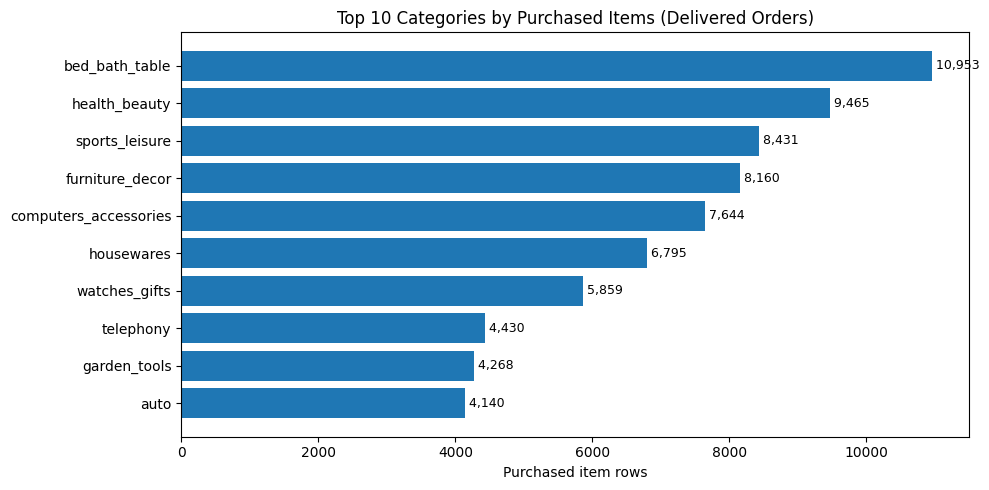

จำนวนหมวดหมู่ทั้งหมด: 74 | สัดส่วน Top 10: 63.65%


In [11]:
# ---------- กราฟ 1: หมวดหมู่ยอดนิยม ----------
category_summary = (
    df_reco.groupby("category_for_model")
    .agg(item_rows=("order_item_id", "size"), unique_orders=("order_id", "nunique"),
         unique_products=("product_id", "nunique"))
    .sort_values("item_rows", ascending=False)
)
top_categories = category_summary.head(10)
display(top_categories)
top10_share = top_categories["item_rows"].sum() / len(df_reco)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_categories.index[::-1], top_categories["item_rows"][::-1])
ax.set_xlabel("Purchased item rows")
ax.set_title("Top 10 Categories by Purchased Items (Delivered Orders)")
for y, value in enumerate(top_categories["item_rows"][::-1]):
    ax.text(value, y, f" {value:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()
print(f"จำนวนหมวดหมู่ทั้งหมด: {len(category_summary):,} | สัดส่วน Top 10: {top10_share:.2%}")

,distinct_products,customers,percent
0,1,88024,94.29
1,2,4574,4.90
2,3,549,0.59
3,4,150,0.16
4,5+,61,0.07


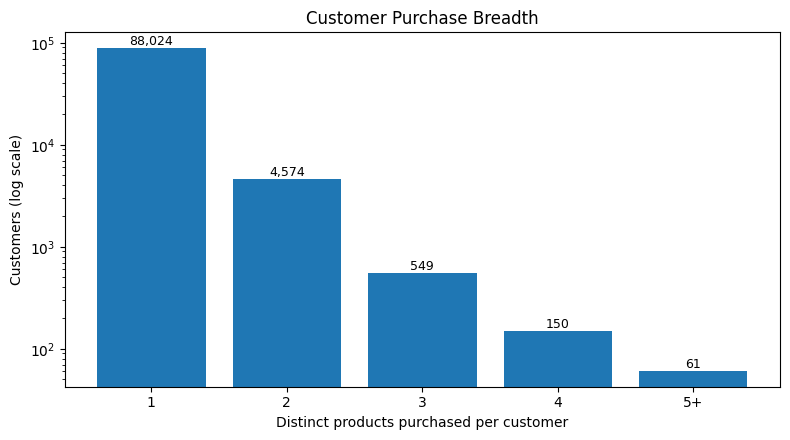

ผู้ซื้อทั้งหมด: 93,358
ผู้ซื้อที่ซื้อสินค้าเพียง 1 ชนิด: 94.29%
ผู้ซื้อที่มีมากกว่า 1 ออเดอร์: 3.00%
สินค้าที่มีผู้ซื้อเพียง 1 คน: 59.52%


In [12]:
# ---------- กราฟ 2: ผู้ซื้อแต่ละคนซื้อสินค้ากี่ชนิด ----------
user_activity = (
    df_reco.groupby("customer_unique_id")
    .agg(n_orders=("order_id", "nunique"), n_products=("product_id", "nunique"),
         n_items=("order_item_id", "size"))
)
activity_bucket = pd.cut(user_activity["n_products"], bins=[0, 1, 2, 3, 4, np.inf],
                         labels=["1", "2", "3", "4", "5+"])
activity_distribution = (
    activity_bucket.value_counts().sort_index()
    .rename_axis("distinct_products").reset_index(name="customers")
)
activity_distribution["percent"] = (
    activity_distribution["customers"].div(len(user_activity)).mul(100).round(2)
)
display(activity_distribution)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(activity_distribution["distinct_products"].astype(str), activity_distribution["customers"])
ax.set_yscale("log")
ax.set_xlabel("Distinct products purchased per customer")
ax.set_ylabel("Customers (log scale)")
ax.set_title("Customer Purchase Breadth")
for x, value in enumerate(activity_distribution["customers"]):
    ax.text(x, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

item_popularity = df_reco.groupby("product_id")["customer_unique_id"].nunique()
pct_single_product_users = user_activity["n_products"].eq(1).mean()
pct_repeat_order_users = user_activity["n_orders"].gt(1).mean()
pct_single_buyer_items = item_popularity.eq(1).mean()
print(f"ผู้ซื้อทั้งหมด: {len(user_activity):,}")
print(f"ผู้ซื้อที่ซื้อสินค้าเพียง 1 ชนิด: {pct_single_product_users:.2%}")
print(f"ผู้ซื้อที่มีมากกว่า 1 ออเดอร์: {pct_repeat_order_users:.2%}")
print(f"สินค้าที่มีผู้ซื้อเพียง 1 คน: {pct_single_buyer_items:.2%}")

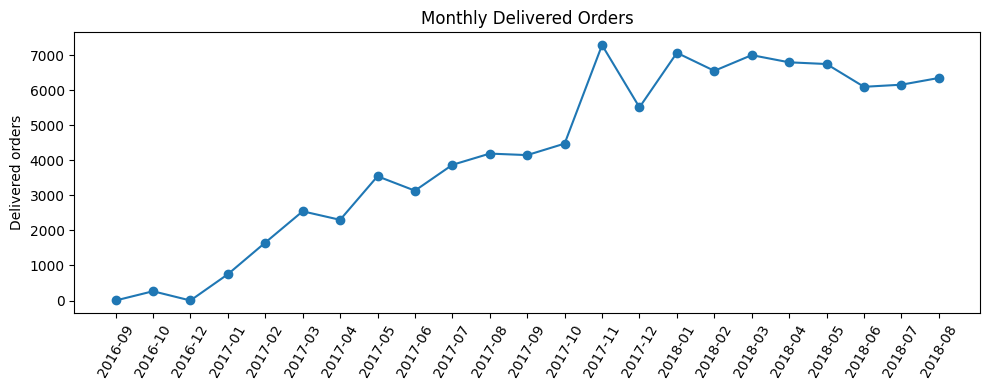

In [13]:
# ---------- กราฟ 3: ปริมาณออเดอร์รายเดือน ----------
monthly_orders = (
    df_reco.groupby(df_reco["order_purchase_timestamp"].dt.to_period("M"))["order_id"].nunique()
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_orders.index.astype(str), monthly_orders.to_numpy(), marker="o")
ax.set_ylabel("Delivered orders")
ax.set_title("Monthly Delivered Orders")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

## 6. Interaction Data & Sparsity

**นิยาม:** หนึ่ง Interaction = ผู้ซื้อ (`customer_unique_id`) หนึ่งคน กับสินค้า (`product_id`) หนึ่งชิ้น ที่เคยซื้อในออเดอร์ `delivered` อย่างน้อยหนึ่งครั้ง (Implicit Feedback แบบ Binary)

- ใช้ `customer_unique_id` เพราะ `customer_id` เปลี่ยนทุกออเดอร์ ผู้ซื้อคนเดิมจะถูกนับเป็นคนละคน
- ใช้ Sparse Matrix (`scipy.sparse.csr_matrix`) เพราะผู้ซื้อหลายหมื่นคน × สินค้าหลายหมื่นชนิด ถ้าใช้ Dense จะกินหน่วยความจำมาก
- Matrix ในส่วนนี้สร้างจากข้อมูลทั้งหมด **เพื่อสำรวจเท่านั้น** ตอนฝึกและประเมินจะสร้างจาก Train หลังแบ่งตามเวลา
- การซื้อไม่ได้แปลว่าผู้ซื้อชอบสินค้าเสมอไป

In [14]:
def build_interactions(df):
    return (
        df.groupby(["customer_unique_id", "product_id"], as_index=False)
        .agg(
            purchase_qty=("order_item_id", "size"),
            n_orders=("order_id", "nunique"),
            first_purchase=("order_purchase_timestamp", "min"),
            last_purchase=("order_purchase_timestamp", "max"),
        )
    )


interactions = build_interactions(df_reco)
interactions["interaction"] = 1
assert not interactions.duplicated(subset=["customer_unique_id", "product_id"]).any()
assert interactions["purchase_qty"].sum() == len(df_reco)

user_ids = pd.Index(interactions["customer_unique_id"].unique()).sort_values()
item_ids = pd.Index(interactions["product_id"].unique()).sort_values()
user_to_idx = pd.Series(range(len(user_ids)), index=user_ids)
item_to_idx = pd.Series(range(len(item_ids)), index=item_ids)

interaction_matrix = csr_matrix(
    (
        interactions["interaction"].to_numpy(dtype="float32"),
        (user_to_idx.loc[interactions["customer_unique_id"]].to_numpy(),
         item_to_idx.loc[interactions["product_id"]].to_numpy()),
    ),
    shape=(len(user_ids), len(item_ids)),
)
n_users, n_items = interaction_matrix.shape
density = interaction_matrix.nnz / (n_users * n_items)
assert interaction_matrix.nnz == len(interactions)
assert len(user_ids) == len(user_activity)

matrix_summary = pd.DataFrame({
    "metric": ["Users", "Items", "Interactions (non-zero)", "Density (%)", "Sparsity (%)"],
    "value": [f"{n_users:,}", f"{n_items:,}", f"{interaction_matrix.nnz:,}",
              f"{density * 100:.5f}", f"{(1 - density) * 100:.5f}"],
})
display(matrix_summary)
print(f"df_reco: {len(df_reco):,} รายการสินค้า → interactions: {len(interactions):,} คู่ผู้ซื้อ–สินค้า")

checkpoint("3 (EDA & interactions)", {
    "users_items_interactions": f"{n_users:,} users | {n_items:,} items | {len(interactions):,} interactions",
    "sparsity_percent": f"{(1 - density) * 100:.5f}",
    "categories_total_and_top10_share": f"{len(category_summary)} categories | top10 share {top10_share:.2%}",
    "pct_users_with_1_product": f"{pct_single_product_users:.2%}",
    "pct_users_with_more_than_1_order": f"{pct_repeat_order_users:.2%}",
    "pct_items_with_1_buyer": f"{pct_single_buyer_items:.2%}",
    "activity_distribution": activity_distribution.to_string(index=False),
})

,metric,value
0,Users,"93,358"
1,Items,"32,216"
2,Interactions (non-zero),"99,785"
3,Density (%),0.00332
4,Sparsity (%),99.99668


df_reco: 110,197 รายการสินค้า → interactions: 99,785 คู่ผู้ซื้อ–สินค้า
===== CHECKPOINT 3 (EDA & interactions) =====
[users_items_interactions]
93,358 users | 32,216 items | 99,785 interactions
[sparsity_percent]
99.99668
[categories_total_and_top10_share]
74 categories | top10 share 63.65%
[pct_users_with_1_product]
94.29%
[pct_users_with_more_than_1_order]
3.00%
[pct_items_with_1_buyer]
59.52%
[activity_distribution]
distinct_products  customers  percent
                1      88024    94.29
                2       4574     4.90
                3        549     0.59
                4        150     0.16
               5+         61     0.07
===== END CHECKPOINT 3 (EDA & interactions) =====


## 7. Temporal Train/Test Split

ระบบแนะนำจริงต้องใช้อดีตทำนายอนาคต การสุ่มแบ่งข้อมูลทำให้โมเดลเห็นข้อมูลอนาคต (Data Leakage)

- **cutoff:** ควอนไทล์ 85% ของเวลาซื้อ ปัดลงเป็นต้นวัน
- **Train:** ซื้อก่อน cutoff / **Test:** ซื้อตั้งแต่ cutoff เป็นต้นไป (ออเดอร์เดียวกันมีเวลาซื้อเดียวกัน จึงไม่ถูกแยกครึ่ง)
- **Ground Truth:** สินค้าที่ผู้ซื้อซื้อในช่วง Test โดยตัดสินค้าที่เคยซื้อใน Train ออก เพราะเราประเมินการแนะนำสินค้า**ใหม่** ไม่ใช่การซื้อซ้ำ
- **Warm Users** = มีประวัติใน Train, **Cold Users** = ไม่มีประวัติใน Train

ข้อจำกัด: สินค้าที่ปรากฏครั้งแรกในช่วง Test ไม่มีโมเดลใดที่ใช้แค่ Train แนะนำได้ ข้อมูลที่เกิดหลัง cutoff ห้ามใช้ฝึกโมเดล

In [15]:
def make_split(df, cutoff, test_end=None):
    t = df["order_purchase_timestamp"]
    in_test = t >= cutoff
    if test_end is not None:
        in_test &= t < test_end
    train_df = df.loc[t < cutoff].copy()
    test_df = df.loc[in_test].copy()
    assert not set(train_df["order_id"]) & set(test_df["order_id"])

    train_inter = build_interactions(train_df)
    test_inter = build_interactions(test_df)
    train_seen = train_inter.groupby("customer_unique_id")["product_id"].agg(set).to_dict()
    train_items = set(train_inter["product_id"])

    pairs = test_inter[["customer_unique_id", "product_id"]].copy()
    pairs["repeat_purchase"] = [
        item in train_seen.get(user, set())
        for user, item in zip(pairs["customer_unique_id"], pairs["product_id"])
    ]
    pairs["item_in_train"] = pairs["product_id"].isin(train_items)
    eval_pairs = pairs.loc[~pairs["repeat_purchase"]]

    ground_truth = eval_pairs.groupby("customer_unique_id")["product_id"].agg(set).to_dict()
    eval_users = sorted(ground_truth)
    return SimpleNamespace(
        cutoff=cutoff, test_end=test_end,
        train_df=train_df, test_df=test_df,
        train_seen=train_seen, train_items=train_items,
        test_pairs=pairs, eval_pairs=eval_pairs, ground_truth=ground_truth,
        eval_users=eval_users,
        warm_users=[u for u in eval_users if u in train_seen],
        cold_users=[u for u in eval_users if u not in train_seen],
    )


cutoff = df_reco["order_purchase_timestamp"].quantile(SPLIT_QUANTILE).normalize()
main = make_split(df_reco, cutoff)
assert len(main.train_df) + len(main.test_df) == len(df_reco)

pct_test_items_unseen = float((~main.eval_pairs["item_in_train"]).mean() * 100)
split_summary = pd.DataFrame({
    "metric": [
        "Cutoff", "Train period", "Test period", "Train item rows", "Test item rows",
        "Train users", "Train items", "Test pairs (all)", "Repeat pairs removed",
        "Evaluated users", "Warm users", "Cold users", "Eval pairs with item not in Train (%)",
    ],
    "value": [
        str(cutoff.date()),
        f"{main.train_df['order_purchase_timestamp'].min().date()} → {main.train_df['order_purchase_timestamp'].max().date()}",
        f"{main.test_df['order_purchase_timestamp'].min().date()} → {main.test_df['order_purchase_timestamp'].max().date()}",
        f"{len(main.train_df):,}", f"{len(main.test_df):,}",
        f"{len(main.train_seen):,}", f"{len(main.train_items):,}",
        f"{len(main.test_pairs):,}", f"{int(main.test_pairs['repeat_purchase'].sum()):,}",
        f"{len(main.eval_users):,}", f"{len(main.warm_users):,}", f"{len(main.cold_users):,}",
        f"{pct_test_items_unseen:.2f}",
    ],
})
display(split_summary)

,metric,value
0,Cutoff,2018-06-20
1,Train period,2016-09-15 → 2018-06-19
2,Test period,2018-06-20 → 2018-08-29
3,Train item rows,"93,572"
4,Test item rows,"16,625"
5,Train users,"79,146"
6,Train items,"27,462"
7,Test pairs (all),"15,249"
8,Repeat pairs removed,37
9,Evaluated users,"14,507"


## 8. Evaluation Framework & Baselines

ใช้ K = 10 (แนะนำ 10 สินค้าต่อผู้ซื้อ) และทุกโมเดลจะไม่แนะนำสินค้าที่ผู้ซื้อเคยซื้อใน Train

| ตัวชี้วัด | ความหมาย |
|---|---|
| Precision@K | สัดส่วนสินค้าที่แนะนำแล้วผู้ซื้อซื้อจริง |
| Recall@K | สัดส่วนสินค้าที่ผู้ซื้อซื้อจริงและอยู่ในรายการแนะนำ |
| **HitRate@K** | สัดส่วนผู้ซื้อที่มีสินค้าถูกต้องอย่างน้อยหนึ่งชิ้นในรายการ (ตัวชี้วัดหลัก อ่านง่ายที่สุด) |
| NDCG@K | เหมือน Recall แต่ให้คะแนนมากขึ้นเมื่อสินค้าที่ถูกอยู่อันดับต้น |
| Item Coverage | สัดส่วนสินค้าใน Train ที่ถูกแนะนำให้ผู้ซื้ออย่างน้อยหนึ่งคน |

ผู้ซื้อส่วนใหญ่ซื้อเพียงหนึ่งสินค้าในช่วง Test ดังนั้น Precision@10 สูงสุดได้ประมาณ 0.1

**Baselines:** Random (ไว้เช็คว่าฟังก์ชันประเมินไม่ผิด), Popularity ตลอดช่วง Train, Popularity ใน 90 วันล่าสุดก่อน cutoff (เพราะความนิยมเปลี่ยนตามเวลา)

In [16]:
def evaluate_topk(recommend_fn, users, ground_truth, n_train_items, k=K):
    if len(users) == 0:
        return {"users": 0}
    discounts = 1 / np.log2(np.arange(2, k + 2))
    recommended_items, scores = set(), []
    for user in users:
        truth = ground_truth[user]
        recs = list(recommend_fn(user, k))[:k]
        recommended_items.update(recs)
        hit_flags = np.array([item in truth for item in recs], dtype=float)
        hits = hit_flags.sum()
        dcg = (hit_flags * discounts[: len(recs)]).sum()
        idcg = discounts[: min(len(truth), k)].sum()
        scores.append([hits / k, hits / len(truth), float(hits > 0), dcg / idcg])
    scores = np.array(scores)
    return {
        "users": len(users),
        f"precision@{k}": scores[:, 0].mean(),
        f"recall@{k}": scores[:, 1].mean(),
        f"hit_rate@{k}": scores[:, 2].mean(),
        f"ndcg@{k}": scores[:, 3].mean(),
        "item_coverage": len(recommended_items) / n_train_items,
    }


def popularity_ranking(df, start=None, top_n=POP_SIZE):
    data = df if start is None else df.loc[df["order_purchase_timestamp"] >= start]
    return (
        data.groupby("product_id")["customer_unique_id"].nunique()
        .sort_values(ascending=False, kind="mergesort")
        .head(top_n).index.tolist()
    )


def make_ranked_recommender(ranking, seen_lookup):
    # แนะนำตามลำดับที่กำหนด โดยข้ามสินค้าที่ผู้ซื้อเคยซื้อใน Train
    def recommend(user, k):
        seen = seen_lookup.get(user, set())
        recs = []
        for item in ranking:
            if item not in seen:
                recs.append(item)
                if len(recs) == k:
                    break
        return recs
    return recommend


def make_random_recommender(train_items, seen_lookup, seed=SEED):
    pool = np.array(sorted(train_items))
    rng = np.random.default_rng(seed)

    def recommend(user, k):
        seen = seen_lookup.get(user, set())
        recs = []
        while len(recs) < k:
            for idx in rng.integers(0, len(pool), size=k * 3):
                item = pool[idx]
                if item not in seen and item not in recs:
                    recs.append(item)
                    if len(recs) == k:
                        break
        return recs
    return recommend

In [17]:
n_train_items = len(main.train_items)
pop_all_ranking = popularity_ranking(main.train_df)
pop_recent_ranking = popularity_ranking(main.train_df, start=cutoff - pd.Timedelta(days=RECENT_DAYS))

baselines = {
    "Random": make_random_recommender(main.train_items, main.train_seen),
    "Popularity (All-time)": make_ranked_recommender(pop_all_ranking, main.train_seen),
    POP_NAME: make_ranked_recommender(pop_recent_ranking, main.train_seen),
}
user_groups = {"All": main.eval_users, "Warm": main.warm_users, "Cold": main.cold_users}

baseline_rows = []
for model_name, fn in baselines.items():
    for group_name, users in user_groups.items():
        baseline_rows.append({
            "model": model_name, "user_group": group_name,
            **evaluate_topk(fn, users, main.ground_truth, n_train_items),
        })
baseline_results = pd.DataFrame(baseline_rows).round(4)
display(baseline_results)

top_recent_items = (
    df_reco.loc[df_reco["product_id"].isin(pop_recent_ranking[:K]), ["product_id", "category_for_model"]]
    .drop_duplicates("product_id").set_index("product_id").loc[pop_recent_ranking[:K]].reset_index()
)
display(top_recent_items)

checkpoint("4 (Split & baselines)", {
    "split_summary": split_summary.to_string(index=False),
    "baseline_results": baseline_results.to_string(index=False),
    "pct_warm_of_eval_users": f"{len(main.warm_users) / len(main.eval_users):.2%}",
})

,model,user_group,users,precision@10,recall@10,hit_rate@10,ndcg@10,item_coverage
0,Random,All,14507,0.0000,0.0003,0.0003,0.0001,0.9951
1,Random,Warm,295,0.0000,0.0000,0.0000,0.0000,0.1023
2,Random,Cold,14212,0.0000,0.0004,0.0004,0.0002,0.9939
3,Popularity (All-time),All,14507,0.0011,0.0105,0.0108,0.0049,0.0004
4,Popularity (All-time),Warm,295,0.0014,0.0096,0.0136,0.0039,0.0004
5,Popularity (All-time),Cold,14212,0.0011,0.0105,0.0108,0.0049,0.0004
6,Popularity (Recent 90d),All,14507,0.0018,0.0177,0.0181,0.0074,0.0004
7,Popularity (Recent 90d),Warm,295,0.0024,0.0198,0.0237,0.0086,0.0004
8,Popularity (Recent 90d),Cold,14212,0.0018,0.0177,0.0179,0.0074,0.0004


,product_id,category_for_model
0,53b36df67ebb7c41585e8d54d6772e08,watches_gifts
1,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor
2,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories
4,422879e10f46682990de24d770e7f83d,garden_tools
5,3fbc0ef745950c7932d5f2a446189725,health_beauty
6,19c91ef95d509ea33eda93495c4d3481,health_beauty
7,a62e25e09e05e6faf31d90c6ec1aa3d1,watches_gifts
8,e0d64dcfaa3b6db5c54ca298ae101d05,watches_gifts
9,2948658cb6abc82847412be7201bfc4c,health_beauty


===== CHECKPOINT 4 (Split & baselines) =====
[split_summary]
                               metric                   value
                               Cutoff              2018-06-20
                         Train period 2016-09-15 → 2018-06-19
                          Test period 2018-06-20 → 2018-08-29
                      Train item rows                  93,572
                       Test item rows                  16,625
                          Train users                  79,146
                          Train items                  27,462
                     Test pairs (all)                  15,249
                 Repeat pairs removed                      37
                      Evaluated users                  14,507
                           Warm users                     295
                           Cold users                  14,212
Eval pairs with item not in Train (%)                   41.39
[baseline_results]
                  model user_group  users  precision

### อ่านผล Baseline

- Popularity ต้องได้คะแนนสูงกว่า Random อย่างชัดเจน ถ้าไม่ เช่นนั้นให้ตรวจการแบ่งข้อมูลหรือฟังก์ชันประเมินผล
- เปรียบเทียบ All-time กับ Recent 90d เพื่อดูว่าความนิยมเปลี่ยนตามเวลาหรือไม่
- Cold Users มีจำนวนมากที่สุดและไม่มีประวัติ ทุกโมเดลจึงเหลือแค่ Popularity กับกลุ่มนี้ การเปรียบเทียบโมเดลที่ใช้ประวัติจึงทำในกลุ่ม Warm
- Item Coverage ของ Popularity ต่ำมาก (ผู้ซื้อเกือบทุกคนได้รายการเหมือนกัน)
- โมเดลถัดไปต้องเอาชนะ Popularity (Recent) อย่างน้อยในกลุ่ม Warm จึงจะถือว่ามีประโยชน์

## 9. Personalized Models & Comparison

| โมเดล | แนวคิด | ใช้กับ |
|---|---|---|
| Item-based CF | แนะนำสินค้าที่มักถูกซื้อโดยผู้ซื้อกลุ่มเดียวกัน (Cosine Similarity ระหว่างสินค้า) | Warm Users |
| Category-Based | แนะนำสินค้ายอดนิยมในหมวดที่ผู้ซื้อเคยซื้อ | Warm Users |
| Hybrid | ใช้ CF ก่อน เติมด้วย Category แล้วเติมด้วย Popularity | ทุกคน |

ทุกโมเดลสร้างจาก Train เท่านั้น และเมื่อหาสินค้าได้ไม่ครบ 10 ชิ้นจะเติมด้วย Popularity (Recent 90d) ดังนั้นสำหรับ Cold Users ทุกโมเดลได้ผลเท่ากับ Popularity

ฟังก์ชัน `build_artifacts` / `recommend_from_artifacts` ด้านล่างเป็นโค้ดชุดเดียวกับที่ใช้ในโมเดลที่ส่งมอบให้ API (ไม่เขียนซ้ำสองแบบ)

In [18]:
def build_artifacts(df, reference_date=None, recent_days=RECENT_DAYS, pop_size=POP_SIZE):
    pairs = df.groupby(["customer_unique_id", "product_id"]).size().reset_index(name="n")
    u_ids = pd.Index(sorted(pairs["customer_unique_id"].unique()))
    i_ids = pd.Index(sorted(pairs["product_id"].unique()))
    u_pos = pd.Series(np.arange(len(u_ids)), index=u_ids)
    i_pos = pd.Series(np.arange(len(i_ids)), index=i_ids)

    X = csr_matrix(
        (np.ones(len(pairs), dtype="float32"),
         (u_pos.loc[pairs["customer_unique_id"]].to_numpy(), i_pos.loc[pairs["product_id"]].to_numpy())),
        shape=(len(u_ids), len(i_ids)),
    )
    # Cosine Similarity ระหว่างสินค้า: normalize ตามคอลัมน์แล้วคูณกัน
    X_norm = normalize(X, norm="l2", axis=0)
    sim = (X_norm.T @ X_norm).tocsr()
    sim = (sim - diags(sim.diagonal())).tocsr()   # ตัดความคล้ายกับตัวเองออก
    sim.eliminate_zeros()

    if reference_date is None:
        reference_date = df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
    pop_ranking = popularity_ranking(
        df, start=reference_date - pd.Timedelta(days=recent_days), top_n=pop_size)
    item_category = (
        df.drop_duplicates("product_id").set_index("product_id")["category_for_model"].to_dict())

    return {
        "model_name": "Item-CF + Popularity (Recent)",
        "trained_until": str(df["order_purchase_timestamp"].max()),
        "reference_date": reference_date,
        "recent_days": recent_days,
        "user_index": dict(zip(u_ids, range(len(u_ids)))),
        "item_ids": np.asarray(i_ids, dtype=object),
        "item_index": dict(zip(i_ids, range(len(i_ids)))),
        "X": X,
        "item_sim": sim,
        "pop_ranking": pop_ranking,
        "item_category": item_category,
    }


def user_seen(art, user):
    u = art["user_index"].get(user)
    if u is None:
        return set()
    return set(art["item_ids"][art["X"][u].indices])


def cf_recommend(art, user, k=K):
    # คืน [(product_id, score)] เฉพาะสินค้าที่ CF score > 0 (อาจได้น้อยกว่า k)
    u = art["user_index"].get(user)
    if u is None:
        return []
    row = art["X"][u]
    scores = (row @ art["item_sim"]).toarray().ravel()
    scores[row.indices] = 0                       # ไม่แนะนำสินค้าที่เคยซื้อแล้ว
    candidates = np.flatnonzero(scores > 0)
    if len(candidates) == 0:
        return []
    order = candidates[np.argsort(-scores[candidates], kind="mergesort")][:k]
    return [(art["item_ids"][i], float(scores[i])) for i in order]


def recommend_from_artifacts(art, customer_id, k=K):
    seen = user_seen(art, customer_id)
    recs = [(item, "similar_items", round(score, 4)) for item, score in cf_recommend(art, customer_id, k)]
    chosen = {item for item, _, _ in recs}
    for item in art["pop_ranking"]:
        if len(recs) >= k:
            break
        if item not in seen and item not in chosen:
            recs.append((item, "popular_recent", None))
            chosen.add(item)
    return [
        {"rank": rank, "product_id": item, "category": art["item_category"].get(item, "unknown"),
         "source": source, "score": score}
        for rank, (item, source, score) in enumerate(recs, start=1)
    ]


def similar_items(art, product_id, k=K):
    # Item-to-item: สินค้าที่มักถูกซื้อร่วมกับสินค้านี้ (ไม่ต้องใช้ประวัติผู้ซื้อ)
    i = art["item_index"].get(product_id)
    if i is None:
        return []
    row = art["item_sim"][i]
    if row.nnz == 0:
        return []
    order = np.argsort(-row.data, kind="mergesort")[:k]
    return [
        {"product_id": art["item_ids"][row.indices[j]],
         "category": art["item_category"].get(art["item_ids"][row.indices[j]], "unknown"),
         "similarity": round(float(row.data[j]), 4)}
        for j in order
    ]

In [19]:
def build_category_recommender(df, seen_lookup, reference_date):
    recent_start = reference_date - pd.Timedelta(days=RECENT_DAYS)
    item_category = df.drop_duplicates("product_id").set_index("product_id")["category_for_model"]

    buyers_recent = (df.loc[df["order_purchase_timestamp"] >= recent_start]
                     .groupby("product_id")["customer_unique_id"].nunique())
    buyers_all = df.groupby("product_id")["customer_unique_id"].nunique()
    item_pop = pd.DataFrame({"recent": buyers_recent, "all_time": buyers_all}).fillna(0)
    item_pop["category"] = item_category
    item_pop = item_pop.sort_values(["recent", "all_time"], ascending=False, kind="mergesort")
    category_rankings = {
        cat: group.index[:POP_SIZE].tolist()
        for cat, group in item_pop.groupby("category", sort=False)
    }

    up = df[["customer_unique_id", "product_id"]].drop_duplicates()
    up["category"] = up["product_id"].map(item_category)
    up = up.loc[up["category"].ne("unknown")]
    user_categories = (
        up.groupby(["customer_unique_id", "category"]).size().reset_index(name="n")
        .sort_values(["customer_unique_id", "n"], ascending=[True, False], kind="mergesort")
        .groupby("customer_unique_id")["category"].agg(list).to_dict()
    )

    def recommend(user, k):
        seen = seen_lookup.get(user, set())
        recs = []
        for cat in user_categories.get(user, []):
            for item in category_rankings.get(cat, []):
                if item not in seen and item not in recs:
                    recs.append(item)
                    if len(recs) == k:
                        return recs
        return recs
    return recommend


def combine(*recommenders):
    # ดึงสินค้าจากแต่ละแหล่งตามลำดับจนครบ k โดยไม่ซ้ำกัน
    def recommend(user, k):
        recs = []
        for fn in recommenders:
            for item in fn(user, k):
                if item not in recs:
                    recs.append(item)
                    if len(recs) == k:
                        return recs
        return recs
    return recommend


def build_models(train_df, train_seen, reference_date):
    art = build_artifacts(train_df, reference_date=reference_date)
    pop_fn = make_ranked_recommender(art["pop_ranking"], train_seen)
    cat_fn = build_category_recommender(train_df, train_seen, reference_date)

    def cf_fn(user, k):
        return [item for item, _ in cf_recommend(art, user, k)]

    models = {
        POP_NAME: pop_fn,
        "Category-Based + Pop": combine(cat_fn, pop_fn),
        "Item-CF + Pop": combine(cf_fn, pop_fn),
        "Hybrid (CF → Category → Pop)": combine(cf_fn, cat_fn, pop_fn),
    }
    return art, models, cf_fn, cat_fn


def per_user_hits(recommend_fn, users, ground_truth, k=K):
    return np.array([
        float(any(item in ground_truth[u] for item in recommend_fn(u, k))) for u in users
    ])


def bootstrap_ci(values, n_boot=N_BOOT, seed=SEED):
    if len(values) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    low, high = np.percentile(values[idx].mean(axis=1), [2.5, 97.5])
    return float(low), float(high)


def summarize_hits(hits_by_model, baseline=POP_NAME):
    rows = []
    for name, hits in hits_by_model.items():
        low, high = bootstrap_ci(hits)
        diff = hits - hits_by_model[baseline]     # เทียบกับผู้ซื้อคนเดียวกัน (paired)
        d_low, d_high = bootstrap_ci(diff)
        rows.append({
            "model": name, "n_users": len(hits), "hits": int(hits.sum()),
            "hit_rate@10": hits.mean() if len(hits) else np.nan,
            "ci_95_low": low, "ci_95_high": high,
            "diff_vs_pop": diff.mean() if len(diff) else np.nan,
            "diff_ci_low": d_low, "diff_ci_high": d_high,
        })
    out = pd.DataFrame(rows)
    out["better_than_pop"] = out["diff_ci_low"] > 0
    return out

In [20]:
art_train, models, cf_fn, cat_fn = build_models(main.train_df, main.train_seen, cutoff)
assert art_train["X"].shape == (len(main.train_seen), len(main.train_items))

# ---------- ตรวจความถูกต้อง ----------
for name, fn in models.items():
    for user in main.warm_users:
        recs = fn(user, K)
        assert len(recs) == K and len(set(recs)) == K, name
        assert not set(recs) & main.train_seen.get(user, set()), name
for user in main.warm_users + main.cold_users[:500]:
    ids = [r["product_id"] for r in recommend_from_artifacts(art_train, user, K)]
    assert ids == models["Item-CF + Pop"](user, K), "recommend_from_artifacts ไม่ตรงกับตอนประเมิน"
print("ผ่าน: ทุกโมเดลคืนสินค้าครบ ไม่ซ้ำ ไม่มีสินค้าที่เคยซื้อ และฟังก์ชันที่ส่งมอบให้ API ให้ผลตรงกับตอนประเมิน")

# ---------- ความครอบคลุมของแต่ละแหล่ง ----------
cf_reach = float(np.mean([len(cf_fn(u, K)) > 0 for u in main.warm_users]))
cat_reach = float(np.mean([len(cat_fn(u, K)) > 0 for u in main.warm_users]))
item_sim_train = art_train["item_sim"]
pct_items_with_neighbors = float((np.diff(item_sim_train.indptr) > 0).mean())
print(f"Warm Users ที่ CF หาสินค้าได้อย่างน้อย 1 ชิ้น: {cf_reach:.2%}")
print(f"Warm Users ที่ Category-Based หาสินค้าได้: {cat_reach:.2%}")
print(f"คู่สินค้าที่มีความคล้าย > 0: {item_sim_train.nnz:,} | สินค้าที่มีสินค้าคล้าย: {pct_items_with_neighbors:.2%}")

# ---------- ประเมินผล ----------
model_rows = []
for name, fn in models.items():
    for group_name in ["Warm", "All"]:
        model_rows.append({
            "model": name, "user_group": group_name,
            **evaluate_topk(fn, user_groups[group_name], main.ground_truth, n_train_items),
        })
model_results_raw = pd.DataFrame(model_rows)
model_results = model_results_raw.round(4)
display(model_results)

# ---------- Bootstrap CI (Warm Users) ----------
warm_hits = {name: per_user_hits(fn, main.warm_users, main.ground_truth) for name, fn in models.items()}
warm_ci = summarize_hits(warm_hits).round(4)
display(warm_ci)

warm_cov = model_results_raw.loc[model_results_raw["user_group"].eq("Warm")].set_index("model")["item_coverage"]
coverage_ratio = float(warm_cov["Item-CF + Pop"] / warm_cov[POP_NAME])
print(f"Item Coverage (Warm): Item-CF + Pop = {warm_cov['Item-CF + Pop']:.4f} | "
      f"{POP_NAME} = {warm_cov[POP_NAME]:.4f} | อัตราส่วน = {coverage_ratio:.1f} เท่า")
print("โมเดลที่ดีกว่า Popularity อย่างมีนัยสำคัญ:",
      warm_ci.loc[warm_ci["better_than_pop"], "model"].tolist() or "ไม่มี")

ผ่าน: ทุกโมเดลคืนสินค้าครบ ไม่ซ้ำ ไม่มีสินค้าที่เคยซื้อ และฟังก์ชันที่ส่งมอบให้ API ให้ผลตรงกับตอนประเมิน
Warm Users ที่ CF หาสินค้าได้อย่างน้อย 1 ชิ้น: 46.78%
Warm Users ที่ Category-Based หาสินค้าได้: 98.31%
คู่สินค้าที่มีความคล้าย > 0: 12,604 | สินค้าที่มีสินค้าคล้าย: 23.96%


,model,user_group,users,precision@10,recall@10,hit_rate@10,ndcg@10,item_coverage
0,Popularity (Recent 90d),Warm,295,0.0024,0.0198,0.0237,0.0086,0.0004
1,Popularity (Recent 90d),All,14507,0.0018,0.0177,0.0181,0.0074,0.0004
2,Category-Based + Pop,Warm,295,0.0020,0.0203,0.0203,0.0108,0.0157
3,Category-Based + Pop,All,14507,0.0018,0.0177,0.0180,0.0075,0.0157
4,Item-CF + Pop,Warm,295,0.0024,0.0198,0.0237,0.0074,0.0154
5,Item-CF + Pop,All,14507,0.0018,0.0177,0.0181,0.0074,0.0154
6,Hybrid (CF → Category → Pop),Warm,295,0.0017,0.0169,0.0169,0.0084,0.0282
7,Hybrid (CF → Category → Pop),All,14507,0.0018,0.0176,0.0179,0.0074,0.0282


,model,n_users,hits,hit_rate@10,ci_95_low,ci_95_high,diff_vs_pop,diff_ci_low,diff_ci_high,better_than_pop
0,Popularity (Recent 90d),295,7,0.0237,0.0068,0.0441,0.0000,0.0000,0.0000,False
1,Category-Based + Pop,295,6,0.0203,0.0068,0.0373,-0.0034,-0.0237,0.0169,False
2,Item-CF + Pop,295,7,0.0237,0.0068,0.0441,0.0000,0.0000,0.0000,False
3,Hybrid (CF → Category → Pop),295,5,0.0169,0.0034,0.0339,-0.0068,-0.0271,0.0102,False


Item Coverage (Warm): Item-CF + Pop = 0.0154 | Popularity (Recent 90d) = 0.0004 | อัตราส่วน = 38.5 เท่า
โมเดลที่ดีกว่า Popularity อย่างมีนัยสำคัญ: ไม่มี


### 9.1 วิธีอ่านผล

- เปรียบเทียบหลักในกลุ่ม **Warm Users** เพราะ Cold Users ทุกโมเดลเหลือแค่ Popularity
- ใช้ Bootstrap 95% CI ของ**ผลต่าง** HitRate (คู่ผู้ซื้อเดียวกัน) เทียบกับ Popularity (Recent 90d) ถ้าช่วงคร่อม 0 ถือว่ายังไม่มีหลักฐานเพียงพอว่าดีกว่า
- พิจารณา Item Coverage ร่วมด้วย โมเดลที่คะแนนใกล้เคียงกันแต่ Coverage สูงกว่า กระจายการแนะนำได้ดีกว่า
- ข้อจำกัด: Warm Users มีน้อย และประมาณ 41% ของคู่ที่ใช้ประเมินเป็นสินค้าที่ไม่มีใน Train
- การเลือกโมเดลและรายงานผลใช้ชุด Test เดียวกัน (Warm Users น้อยเกินกว่าจะแยก Validation) จึงตรวจซ้ำแบบ Rolling ใน Section 10

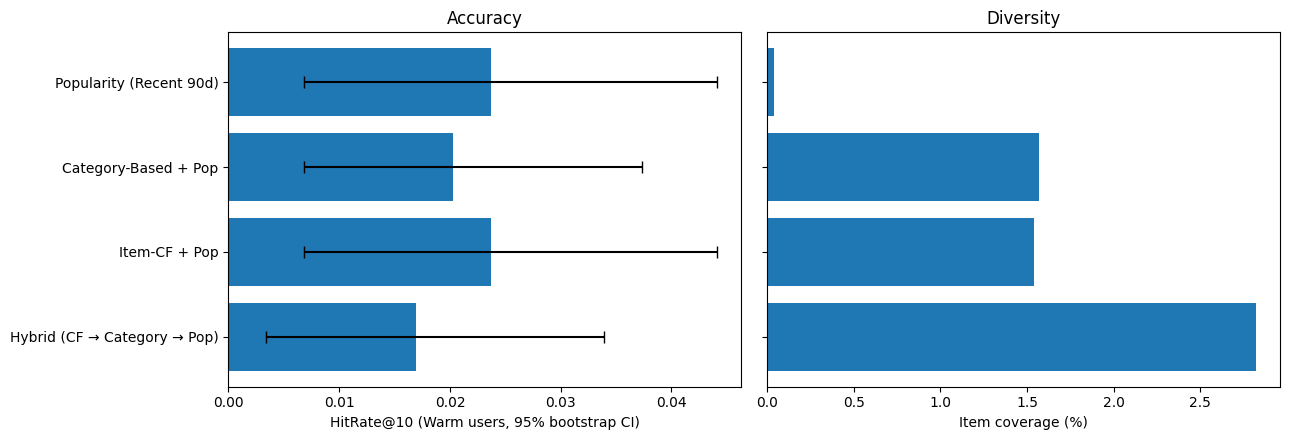

===== CHECKPOINT 5 (Model comparison, main split) =====
[model_results]
                       model user_group  users  precision@10  recall@10  hit_rate@10  ndcg@10  item_coverage
     Popularity (Recent 90d)       Warm    295        0.0024     0.0198       0.0237   0.0086         0.0004
     Popularity (Recent 90d)        All  14507        0.0018     0.0177       0.0181   0.0074         0.0004
        Category-Based + Pop       Warm    295        0.0020     0.0203       0.0203   0.0108         0.0157
        Category-Based + Pop        All  14507        0.0018     0.0177       0.0180   0.0075         0.0157
               Item-CF + Pop       Warm    295        0.0024     0.0198       0.0237   0.0074         0.0154
               Item-CF + Pop        All  14507        0.0018     0.0177       0.0181   0.0074         0.0154
Hybrid (CF → Category → Pop)       Warm    295        0.0017     0.0169       0.0169   0.0084         0.0282
Hybrid (CF → Category → Pop)        All  14507        0.

In [21]:
plot_df = warm_ci.merge(
    model_results.loc[model_results["user_group"].eq("Warm"), ["model", "item_coverage"]], on="model")
y = np.arange(len(plot_df))
err = np.vstack([
    plot_df["hit_rate@10"] - plot_df["ci_95_low"],
    plot_df["ci_95_high"] - plot_df["hit_rate@10"],
]).clip(min=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(y, plot_df["hit_rate@10"], xerr=err, capsize=4)
axes[0].set_yticks(y, plot_df["model"])
axes[0].invert_yaxis()
axes[0].set_xlabel("HitRate@10 (Warm users, 95% bootstrap CI)")
axes[0].set_title("Accuracy")
axes[1].barh(y, plot_df["item_coverage"] * 100)
axes[1].set_yticks(y, [])
axes[1].invert_yaxis()
axes[1].set_xlabel("Item coverage (%)")
axes[1].set_title("Diversity")
plt.tight_layout()
plt.show()

checkpoint("5 (Model comparison, main split)", {
    "model_results": model_results.to_string(index=False),
    "warm_bootstrap_ci": warm_ci.to_string(index=False),
    "cf_reach_warm": f"{cf_reach:.2%}",
    "category_reach_warm": f"{cat_reach:.2%}",
    "item_sim_pairs_and_items_with_neighbors": f"{item_sim_train.nnz:,} pairs | {pct_items_with_neighbors:.2%} of items",
    "coverage_ratio_cf_vs_pop": f"{coverage_ratio:.1f}x",
})

## 10. Robustness: Rolling-Origin Evaluation

Warm Users ในการแบ่งครั้งเดียวมีเพียง 295 คน ผลจึงไม่นิ่ง ส่วนนี้ประเมินซ้ำด้วย cutoff เพิ่มอีก 2 ช่วงเวลา (หน้าต่าง Test ยาวเท่ากัน ไม่ซ้อนทับกัน) แล้วรวมผู้ซื้อ Warm จากทุกช่วงมาคำนวณ HitRate และ Bootstrap CI ใหม่

- แต่ละช่วงสร้างโมเดลจากข้อมูลก่อน cutoff ของช่วงนั้นเท่านั้น
- ผู้ซื้อคนเดียวกันอาจปรากฏในหลายช่วงได้ (นับเป็นคนละเคส) จึงเป็นการประมาณคร่าวๆ ไม่ใช่การทดสอบทางสถิติที่เข้มงวด

In [22]:
span_days = (df_reco["order_purchase_timestamp"].max() - cutoff).days + 1
span = pd.Timedelta(days=span_days)
fold_specs = [
    ("fold0 (main)", cutoff, None),
    ("fold1", cutoff - span, cutoff),
    ("fold2", cutoff - 2 * span, cutoff - span),
]

fold_hits = {"fold0 (main)": warm_hits}
fold_rows = [{
    "fold": "fold0 (main)", "cutoff": str(cutoff.date()), "test_end": "end of data",
    "eval_users": len(main.eval_users), "warm_users": len(main.warm_users),
    **{m: float(h.mean()) for m, h in warm_hits.items()},
}]

for name, c, end in fold_specs[1:]:
    split = make_split(df_reco, c, end)
    _, fold_models, _, _ = build_models(split.train_df, split.train_seen, c)
    hits = {m: per_user_hits(fn, split.warm_users, split.ground_truth) for m, fn in fold_models.items()}
    fold_hits[name] = hits
    fold_rows.append({
        "fold": name, "cutoff": str(c.date()), "test_end": str(end.date()),
        "eval_users": len(split.eval_users), "warm_users": len(split.warm_users),
        **{m: (float(h.mean()) if len(h) else np.nan) for m, h in hits.items()},
    })

fold_table = pd.DataFrame(fold_rows).round(4)
display(fold_table)

pooled_hits = {m: np.concatenate([fold_hits[f][m] for f in fold_hits]) for m in models}
rolling_pooled = summarize_hits(pooled_hits).round(4)
display(rolling_pooled)
print("โมเดลที่ดีกว่า Popularity อย่างมีนัยสำคัญ (ข้อมูลรวม):",
      rolling_pooled.loc[rolling_pooled["better_than_pop"], "model"].tolist() or "ไม่มี")

checkpoint("6 (Rolling-origin)", {
    "fold_table": fold_table.to_string(index=False),
    "pooled_warm_results": rolling_pooled.to_string(index=False),
})

,fold,cutoff,test_end,eval_users,warm_users,Popularity (Recent 90d),Category-Based + Pop,Item-CF + Pop,Hybrid (CF → Category → Pop)
0,fold0 (main),2018-06-20,end of data,14507,295,0.0237,0.0203,0.0237,0.0169
1,fold1,2018-04-10,2018-06-20,15213,308,0.0195,0.0325,0.0195,0.0325
2,fold2,2018-01-29,2018-04-10,15962,241,0.0249,0.0249,0.0415,0.0290


,model,n_users,hits,hit_rate@10,ci_95_low,ci_95_high,diff_vs_pop,diff_ci_low,diff_ci_high,better_than_pop
0,Popularity (Recent 90d),844,19,0.0225,0.0130,0.0332,0.0000,0.0000,0.0000,False
1,Category-Based + Pop,844,22,0.0261,0.0154,0.0367,0.0036,-0.0095,0.0166,False
2,Item-CF + Pop,844,23,0.0273,0.0166,0.0391,0.0047,-0.0012,0.0118,False
3,Hybrid (CF → Category → Pop),844,22,0.0261,0.0154,0.0367,0.0036,-0.0107,0.0166,False


โมเดลที่ดีกว่า Popularity อย่างมีนัยสำคัญ (ข้อมูลรวม): ไม่มี
===== CHECKPOINT 6 (Rolling-origin) =====
[fold_table]
        fold     cutoff    test_end  eval_users  warm_users  Popularity (Recent 90d)  Category-Based + Pop  Item-CF + Pop  Hybrid (CF → Category → Pop)
fold0 (main) 2018-06-20 end of data       14507         295                   0.0237                0.0203         0.0237                        0.0169
       fold1 2018-04-10  2018-06-20       15213         308                   0.0195                0.0325         0.0195                        0.0325
       fold2 2018-01-29  2018-04-10       15962         241                   0.0249                0.0249         0.0415                        0.0290
[pooled_warm_results]
                       model  n_users  hits  hit_rate@10  ci_95_low  ci_95_high  diff_vs_pop  diff_ci_low  diff_ci_high  better_than_pop
     Popularity (Recent 90d)      844    19       0.0225     0.0130      0.0332       0.0000       0.0000        0.00

## 11. Final Model, Export & Demo

ประเมินผลด้วย Train แล้ว ก่อนนำไปใช้งานจริงจะฝึกโมเดลใหม่ด้วยข้อมูลทั้งหมด (`df_reco`) เพื่อให้โมเดลรู้จักผู้ซื้อและสินค้าล่าสุด

- ไฟล์โมเดลเก็บเป็นข้อมูลล้วน (Matrix, ID, ลำดับความนิยม) ไม่ใช่ Object ของ Class เพื่อให้ API โหลดได้โดยไม่ต้องมีโค้ดจาก Notebook
- โครงสร้างไฟล์ใช้ key เดิมทั้งหมด (เพิ่ม `item_index` สำหรับ item-to-item) จึงไม่กระทบ `recommender.py` เดิม
- ไฟล์โมเดลมี `user_index` และ Matrix การซื้อ ซึ่งสืบมาจากข้อมูล Olist (CC BY-NC-SA 4.0) ควรระบุที่มาและเงื่อนไขการใช้งานใน README

In [23]:
artifacts = build_artifacts(df_reco)
assert artifacts["X"].shape == interaction_matrix.shape

pick = warm_ci.set_index("model").loc["Item-CF + Pop"]
pooled_pick = rolling_pooled.set_index("model").loc["Item-CF + Pop"]
artifacts["evaluation"] = {
    "cutoff": str(cutoff.date()),
    "warm_users": len(main.warm_users),
    "warm_hits": int(pick["hits"]),
    "warm_hit_rate@10": float(pick["hit_rate@10"]),
    "warm_hit_rate_ci95": [float(pick["ci_95_low"]), float(pick["ci_95_high"])],
    "warm_item_coverage": float(warm_cov["Item-CF + Pop"]),
    "pop_item_coverage": float(warm_cov[POP_NAME]),
    "rolling_warm_cases": int(pooled_pick["n_users"]),
    "rolling_hit_rate@10": float(pooled_pick["hit_rate@10"]),
    "rolling_hit_rate_ci95": [float(pooled_pick["ci_95_low"]), float(pooled_pick["ci_95_high"])],
}

MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "recommender_itemcf_v1.joblib"
joblib.dump(artifacts, MODEL_PATH, compress=3)
model = joblib.load(MODEL_PATH)

for u in list(model["user_index"])[:200]:
    a = [r["product_id"] for r in recommend_from_artifacts(model, u, K)]
    b = [r["product_id"] for r in recommend_from_artifacts(artifacts, u, K)]
    assert a == b
model_mb = MODEL_PATH.stat().st_size / 1e6
print(f"บันทึกไฟล์: {MODEL_PATH} ({model_mb:.2f} MB)")
print(f"ผู้ซื้อ: {len(model['user_index']):,} | สินค้า: {len(model['item_ids']):,}")
print(f"ข้อมูลถึง: {model['trained_until']}")
print(f"ช่วงความนิยมล่าสุด: {(model['reference_date'] - pd.Timedelta(days=RECENT_DAYS)):%Y-%m-%d} "
      f"→ {model['reference_date']:%Y-%m-%d}")

บันทึกไฟล์: models/recommender_itemcf_v1.joblib (3.87 MB)
ผู้ซื้อ: 93,358 | สินค้า: 32,216
ข้อมูลถึง: 2018-08-29 15:00:37
ช่วงความนิยมล่าสุด: 2018-06-01 → 2018-08-30


In [24]:
def recommend_for_customer(customer_id, k=K, art=model):
    return pd.DataFrame(recommend_from_artifacts(art, customer_id, k))


# ผู้ซื้อที่มีประวัติ และ CF หาสินค้าคล้ายได้
multi_buyers = user_activity.query("n_products >= 2").index
demo_user = next(
    u for u in multi_buyers if recommend_from_artifacts(model, u, K)[0]["source"] == "similar_items")

print("ประวัติการซื้อ:")
display(
    df_reco.loc[df_reco["customer_unique_id"].eq(demo_user),
                ["order_purchase_timestamp", "product_id", "category_for_model"]]
    .drop_duplicates("product_id").sort_values("order_purchase_timestamp"))
print("รายการแนะนำ:")
display(recommend_for_customer(demo_user))
print("ผู้ซื้อใหม่ (ไม่มีประวัติ):")
display(recommend_for_customer("new_customer_demo"))

print("Item-to-item (สินค้าที่มักถูกซื้อร่วมกัน):")
first_item_with_neighbors = int(np.flatnonzero(np.diff(model["item_sim"].indptr) > 0)[0])
demo_item = model["item_ids"][first_item_with_neighbors]
display(pd.DataFrame(similar_items(model, demo_item, 5)))

# ความเร็วต่อคำขอ
sample_users = list(model["user_index"])[:1000]
start = time.perf_counter()
for u in sample_users:
    recommend_from_artifacts(model, u, K)
latency_ms = (time.perf_counter() - start) / len(sample_users) * 1000
print(f"เวลาเฉลี่ยต่อคำขอ (ในหน่วยความจำ ไม่รวม HTTP): {latency_ms:.2f} ms")

ประวัติการซื้อ:


,order_purchase_timestamp,product_id,category_for_model
29664,2018-02-28 11:15:41,62984ea1bba7fcea1f5b57084d3bf885,sports_leisure
29665,2018-02-28 11:15:41,58727e154e8e85d84052cd22b0136c84,sports_leisure


รายการแนะนำ:


,rank,product_id,category,source,score
0,1,71b7bb7d435217ef96c1ec8e48421599,sports_leisure,similar_items,0.2887
1,2,19c91ef95d509ea33eda93495c4d3481,health_beauty,popular_recent,NaN
2,3,a92930c327948861c015c919a0bcb4a8,watches_gifts,popular_recent,NaN
3,4,3fbc0ef745950c7932d5f2a446189725,health_beauty,popular_recent,NaN
4,5,e7cc48a9daff5436f63d3aad9426f28b,telephony,popular_recent,NaN
5,6,2fea0f2cec6b6324a277d4a61c2ed2c6,health_beauty,popular_recent,NaN
6,7,fbce4c4cb307679d89a3bf3d3bb353b9,bed_bath_table,popular_recent,NaN
7,8,d04857e7b4b708ee8b8b9921163edba3,computers_accessories,popular_recent,NaN
8,9,73326828aa5efe1ba096223de496f596,food,popular_recent,NaN
9,10,bb50f2e236e5eea0100680137654686c,health_beauty,popular_recent,NaN


ผู้ซื้อใหม่ (ไม่มีประวัติ):


,rank,product_id,category,source,score
0,1,19c91ef95d509ea33eda93495c4d3481,health_beauty,popular_recent,None
1,2,a92930c327948861c015c919a0bcb4a8,watches_gifts,popular_recent,None
2,3,3fbc0ef745950c7932d5f2a446189725,health_beauty,popular_recent,None
3,4,e7cc48a9daff5436f63d3aad9426f28b,telephony,popular_recent,None
4,5,2fea0f2cec6b6324a277d4a61c2ed2c6,health_beauty,popular_recent,None
5,6,fbce4c4cb307679d89a3bf3d3bb353b9,bed_bath_table,popular_recent,None
6,7,d04857e7b4b708ee8b8b9921163edba3,computers_accessories,popular_recent,None
7,8,73326828aa5efe1ba096223de496f596,food,popular_recent,None
8,9,bb50f2e236e5eea0100680137654686c,health_beauty,popular_recent,None
9,10,4fe644d766c7566dbc46fb851363cb3b,art,popular_recent,None


Item-to-item (สินค้าที่มักถูกซื้อร่วมกัน):


,product_id,category,similarity
0,401717fdb76bea40aad511f64ab03c92,auto,1.0000
1,5a6849f9db912b68be72145d959d61d2,auto,1.0000
2,cae8c962ad47ff05a508e6fec4146e1a,auto,0.7071


เวลาเฉลี่ยต่อคำขอ (ในหน่วยความจำ ไม่รวม HTTP): 0.43 ms


In [25]:
# ---------- requirements.txt (pin เวอร์ชันที่ติดตั้งอยู่) ----------
from importlib import metadata


def pin(pkg):
    try:
        return f"{pkg}=={metadata.version(pkg)}", True
    except metadata.PackageNotFoundError:
        return pkg, False


runtime_packages = ["numpy", "scipy", "pandas", "joblib", "streamlit", "fastapi", "uvicorn"]
pins = [pin(p) for p in runtime_packages]
req_lines = [f"# model trained with Python {sys.version.split()[0]}"] + [line for line, _ in pins]
Path("requirements.txt").write_text("\n".join(req_lines) + "\n", encoding="utf-8")
unpinned = [line for line, ok in pins if not ok]
print("\n".join(req_lines))
if unpinned:
    print("\n[!] ยังไม่ได้ pin (ไม่ได้ติดตั้งใน environment นี้):", unpinned,
          "-> pin จาก environment ที่รัน app/api จริง ด้วย pip freeze")


def _json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return str(obj)


checkpoint("7 (Final model & export)", {
    "model_file": f"{MODEL_PATH} ({model_mb:.2f} MB)",
    "users_items": f"{len(model['user_index']):,} users | {len(model['item_ids']):,} items",
    "trained_until": model["trained_until"],
    "latency_ms_per_request": f"{latency_ms:.2f}",
    "evaluation_saved_in_model": json.dumps(artifacts["evaluation"], default=_json_default),
    "requirements_unpinned": unpinned,
})

Path("results_summary.json").write_text(
    json.dumps({"checkpoints": CHECKPOINTS, "evaluation": artifacts["evaluation"]},
               default=_json_default, ensure_ascii=False, indent=2),
    encoding="utf-8")

try:
    from google.colab import files
    for p in [MODEL_PATH, Path("requirements.txt"), Path("results_summary.json")]:
        files.download(str(p))
except ImportError:
    print("ไม่ได้รันบน Colab: ไฟล์อยู่ที่ models/, requirements.txt, results_summary.json")

# model trained with Python 3.13.16
numpy==2.1.3
scipy==1.16.3
pandas==2.2.3
joblib==1.6.0
streamlit
fastapi==0.141.1
uvicorn==0.54.0

[!] ยังไม่ได้ pin (ไม่ได้ติดตั้งใน environment นี้): ['streamlit'] -> pin จาก environment ที่รัน app/api จริง ด้วย pip freeze
===== CHECKPOINT 7 (Final model & export) =====
[model_file]
models/recommender_itemcf_v1.joblib (3.87 MB)
[users_items]
93,358 users | 32,216 items
[trained_until]
2018-08-29 15:00:37
[latency_ms_per_request]
0.43
[evaluation_saved_in_model]
{"cutoff": "2018-06-20", "warm_users": 295, "warm_hits": 7, "warm_hit_rate@10": 0.0237, "warm_hit_rate_ci95": [0.0068, 0.0441], "warm_item_coverage": 0.01540310246886607, "pop_item_coverage": 0.000400553492098172, "rolling_warm_cases": 844, "rolling_hit_rate@10": 0.0273, "rolling_hit_rate_ci95": [0.0166, 0.0391]}
[requirements_unpinned]
['streamlit']
===== END CHECKPOINT 7 (Final model & export) =====


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusion

### ผลลัพธ์

- โมเดลที่ส่งมอบ: **Item-based CF เติมด้วย Popularity (Recent 90d)**
- กลุ่ม Warm Users (n=295): HitRate@10 = 0.0237 (7 คน, 95% CI 0.0068–0.0441) **เท่ากับ** Popularity (Recent 90d) ไม่ได้ดีกว่า
- Item Coverage (Warm) 1.54% เทียบกับ 0.04% ของ Popularity (สูงกว่า 38.5 เท่า) แนะนำสินค้าหลากหลายขึ้นโดยความแม่นยำใน HitRate ไม่ลดลง
- ไม่มีโมเดลใดดีกว่า Popularity อย่างมีนัยสำคัญ (Bootstrap CI ของผลต่างคร่อม 0)
- NDCG@10 ในกลุ่ม Warm ของ Item-CF (0.0074) ต่ำกว่า Popularity (0.0086) เล็กน้อย จึงสรุปได้เพียงว่า "เท่ากัน" ไม่ใช่ "ดีกว่า"
- ตรวจซ้ำแบบ Rolling-Origin (3 ช่วงเวลา, 844 เคส Warm): Item-CF + Pop ได้ 0.0273 (23 hits) เทียบกับ Popularity 0.0225 (19 hits) ไม่ด้อยกว่าในทุกช่วง (เท่ากัน 2 ช่วง ดีกว่า 1 ช่วง) แต่ผลต่าง +0.0047 มี 95% CI −0.0012 ถึง +0.0118 จึงยังไม่มีนัยสำคัญทางสถิติ

### ข้อค้นพบ

- ผู้ซื้อ 94.29% ซื้อสินค้าเพียงชนิดเดียว และ Matrix มี Sparsity 99.997%
- ผู้ถูกประเมิน 98% ไม่มีประวัติใน Train (Cold Start)
- 41.39% ของคู่ที่ใช้ประเมินเป็นสินค้าที่ไม่เคยปรากฏใน Train
- ข้อมูลลักษณะนี้ทำให้ Popularity เป็น Baseline ที่เอาชนะได้ยาก และ CF ให้ผลได้เฉพาะผู้ซื้อที่เคยซื้อซ้ำ (CF หาสินค้าได้ให้ Warm Users เพียง 46.78% ที่เหลือถูกเติมด้วย Popularity)

### ข้อจำกัด

- Warm Users มีน้อย ผลจึงไม่แน่นอนสูง (Rolling ช่วยให้ข้อมูลมากขึ้นแต่ยังไม่ใช่การทดสอบที่เข้มงวด)
- ใช้ชุด Test ทั้งเลือกโมเดลและรายงานผล (ไม่มีชุด Validation แยก)
- การซื้อเป็น Implicit Feedback ไม่ได้แปลว่าผู้ซื้อชอบสินค้าเสมอไป
- ประเมินแบบ Offline เท่านั้น ยังไม่ผ่าน A/B Testing จึงยังสรุปผลต่อยอดขายไม่ได้
- "Real-time" หมายถึงการตอบผลแนะนำทันทีผ่าน API ส่วนโมเดลฝึกใหม่เป็นรอบ (Batch) ไม่ได้อัปเดตทันทีเมื่อมีการซื้อ

### แนวทางพัฒนาต่อ

- ใช้ข้อมูลการเข้าชมหรือการใส่ตะกร้า เพื่อเพิ่มจำนวน Interaction
- ใช้ Content-Based จากข้อความหรือรูปภาพ สำหรับสินค้าใหม่และ Cold Start
- ทดสอบกับผู้ใช้จริงด้วย A/B Testing
